# Kruskal's Algorithm using DSU Data Structure

Let G = (V, E) be a connected, weighted, undirected graph, where:

- V is the set of vertices,
- E is the set of edges, and
- w(e) is the weight of edge e.

The objective is to find a spanning tree T such that:

```text
|T| = |V| - 1
```

and its total weight

```text
w(T) = sum of w(e), for all edges e in T
```

is minimum.

This notebook studies Kruskal's algorithm, cycle detection using Disjoint Set Union, and the running-time effect of Bubble Sort and Merge Sort.


# Kruskal's Algorithm

Let the edges be arranged as:

```text
w(e1) <= w(e2) <= ... <= w(em), where m = |E|.
```

Kruskal's algorithm begins with an empty forest:

```text
F0 = empty set.
```

At stage i, the edge ei = {u, v} is added if and only if u and v belong to different connected components.

```text
Fi = F(i-1) union {ei},  if u and v are in different components,
Fi = F(i-1),             otherwise.
```

The algorithm stops when:

```text
|Fi| = |V| - 1.
```

## Pseudocode

```text
KRUSKAL(V, E)
    Sort the edges in nondecreasing order of weight

    For every vertex v in V
        MAKE-SET(v)

    T = empty set

    For every edge (u, v, w) in sorted order
        If FIND-SET(u) != FIND-SET(v)
            Add (u, v, w) to T
            UNION(u, v)

        If |T| = |V| - 1
            Stop

    Return T
```

## Why is an edge rejected?

If `Find(u) = Find(v)`, a path from u to v already exists. Adding the edge {u, v} creates a cycle. If `Find(u) != Find(v)`, the edge joins two different components.

## Time complexity

For m = |E| edges:

```text
Kruskal time = sorting time + DSU time.
```

With path compression and union by rank, the DSU operations are nearly linear. Sorting therefore dominates:

```text
Bubble Sort: Theta(m^2)
Merge Sort:  Theta(m log m)
```


# Input Graph

Represent every edge as `(u, v, weight)`. Replace the lists below to test another connected weighted graph.


In [1]:
vertices = ['A', 'B', 'C', 'D', 'E', 'F']

edges = [
    ('A', 'B', 4),
    ('A', 'C', 4),
    ('B', 'C', 2),
    ('B', 'D', 5),
    ('C', 'D', 5),
    ('C', 'E', 11),
    ('D', 'E', 2),
    ('D', 'F', 6),
    ('E', 'F', 1)
]

print('Vertices:', vertices)
print('Edges:')
for edge in edges:
    print(edge)


Vertices: ['A', 'B', 'C', 'D', 'E', 'F']
Edges:
('A', 'B', 4)
('A', 'C', 4)
('B', 'C', 2)
('B', 'D', 5)
('C', 'D', 5)
('C', 'E', 11)
('D', 'E', 2)
('D', 'F', 6)
('E', 'F', 1)


# Disjoint Set Union Data Structure

A **Disjoint Set Union**, abbreviated as **DSU**, maintains a collection of pairwise disjoint sets.

For Kruskal's algorithm, each set represents one connected component of the forest currently being constructed.

DSU supports three operations:

1. `make_set(v)` creates the singleton set `{v}`.
2. `find_set(v)` returns the representative of the set containing `v`.
3. `union_sets(u, v)` merges the sets containing `u` and `v`.

The DSU is stored using two dictionaries:

```text
parent[v] = parent of vertex v in the DSU tree
rank[v]   = an upper bound on the height of that tree
```

A root is its own parent:

```text
parent[root] = root
```

Two vertices are in the same connected component exactly when:

```text
find_set(u) == find_set(v)
```

The implementation uses:

- **path compression**, which makes vertices point closer to the root during `find_set`; and
- **union by rank**, which attaches the shorter tree below the taller tree.




In [2]:
# DSU storage
parent = {}
rank = {}


def make_set(vertex):
    parent[vertex] = vertex
    rank[vertex] = 0


def find_set(vertex):
    if parent[vertex] != vertex:
        parent[vertex] = find_set(parent[vertex])
    return parent[vertex]


def union_sets(vertex_1, vertex_2):
    root_1 = find_set(vertex_1)
    root_2 = find_set(vertex_2)

    if root_1 == root_2:
        return False

    if rank[root_1] < rank[root_2]:
        parent[root_1] = root_2
    elif rank[root_1] > rank[root_2]:
        parent[root_2] = root_1
    else:
        parent[root_2] = root_1
        rank[root_1] += 1

    return True


## Test the DSU

Initially, every vertex forms a separate set. After `union_sets('A', 'B')`, vertices `A` and `B` must have the same representative.


In [3]:
parent.clear()
rank.clear()

for vertex in vertices:
    make_set(vertex)

print('Initial representatives:')
for vertex in vertices:
    print(vertex, '->', find_set(vertex))

union_sets('A', 'B')

print()
print('After Union(A, B):')
print('Find(A) =', find_set('A'))
print('Find(B) =', find_set('B'))


Initial representatives:
A -> A
B -> B
C -> C
D -> D
E -> E
F -> F

After Union(A, B):
Find(A) = A
Find(B) = A


# Bubble Sort for the Edge List

Bubble Sort repeatedly compares adjacent edges and exchanges them when their weights are in the wrong order.

For an edge `(u, v, weight)`, the weight is stored at index `2`.

```text
Worst-case sorting time = Theta(m^2)
```

where `m` is the number of edges.


In [4]:
def bubble_sort_edges(edges):
    sorted_edges = edges.copy()
    comparisons = 0

    for pass_number in range(len(sorted_edges) - 1):
        swapped = False

        for index in range(len(sorted_edges) - 1 - pass_number):
            comparisons += 1

            if sorted_edges[index][2] > sorted_edges[index + 1][2]:
                sorted_edges[index], sorted_edges[index + 1] = (
                    sorted_edges[index + 1], sorted_edges[index]
                )
                swapped = True

        if not swapped:
            break

    return sorted_edges, comparisons


## Check Bubble Sort


In [5]:
bubble_sorted_edges, bubble_comparisons = bubble_sort_edges(edges)

print('Edges sorted using Bubble Sort:')
for edge in bubble_sorted_edges:
    print(edge)

print('Number of comparisons:', bubble_comparisons)


Edges sorted using Bubble Sort:
('E', 'F', 1)
('B', 'C', 2)
('D', 'E', 2)
('A', 'B', 4)
('A', 'C', 4)
('B', 'D', 5)
('C', 'D', 5)
('D', 'F', 6)
('C', 'E', 11)
Number of comparisons: 36


# Merge Sort for the Edge List

Merge Sort divides the edge list into two halves, recursively sorts the halves, and merges them in nondecreasing order of weight.

```text
Sorting time = Theta(m log m)
```

Bubble Sort and Merge Sort are kept in separate sections so that each algorithm can be studied and written independently.


In [6]:
def merge_sort_edges(edges):
    if len(edges) <= 1:
        return edges.copy(), 0

    middle = len(edges) // 2

    left, left_comparisons = merge_sort_edges(edges[:middle])
    right, right_comparisons = merge_sort_edges(edges[middle:])

    merged = []
    left_index = 0
    right_index = 0
    merge_comparisons = 0

    while left_index < len(left) and right_index < len(right):
        merge_comparisons += 1

        if left[left_index][2] <= right[right_index][2]:
            merged.append(left[left_index])
            left_index += 1
        else:
            merged.append(right[right_index])
            right_index += 1

    merged.extend(left[left_index:])
    merged.extend(right[right_index:])

    total_comparisons = (
        left_comparisons
        + right_comparisons
        + merge_comparisons
    )

    return merged, total_comparisons


## Check Merge Sort


In [7]:
merge_sorted_edges, merge_comparisons = merge_sort_edges(edges)

print('Edges sorted using Merge Sort:')
for edge in merge_sorted_edges:
    print(edge)

print('Number of comparisons:', merge_comparisons)


Edges sorted using Merge Sort:
('E', 'F', 1)
('B', 'C', 2)
('D', 'E', 2)
('A', 'B', 4)
('A', 'C', 4)
('B', 'D', 5)
('C', 'D', 5)
('D', 'F', 6)
('C', 'E', 11)
Number of comparisons: 19


# Kruskal's Algorithm Using DSU

The sorting function is passed as an argument. Therefore, the same Kruskal code can be used with Bubble Sort or Merge Sort.

For every edge `(u, v, weight)`:

```text
If find_set(u) != find_set(v):
    accept the edge
    union the two sets
Else:
    reject the edge because it creates a cycle
```

The code below is explicit and notebook-friendly. Each statement corresponds directly to one step of the algorithm.


In [8]:
def kruskal(vertices, edges, sorting_function, show_steps=False):
    global parent, rank

    # Step 1: Sort the edges.
    sorted_edges, sorting_comparisons = sorting_function(edges)

    # Step 2: Initially, every vertex is in a separate set.
    parent = {}
    rank = {}

    for vertex in vertices:
        make_set(vertex)

    # Step 3: Start with an empty spanning tree.
    mst_edges = []
    total_weight = 0

    # Step 4: Examine the edges in nondecreasing order.
    for u, v, weight in sorted_edges:
        representative_u = find_set(u)
        representative_v = find_set(v)

        if representative_u != representative_v:
            mst_edges.append((u, v, weight))
            total_weight += weight
            union_sets(u, v)
            decision = 'ACCEPTED'
        else:
            decision = 'REJECTED: cycle'

        if show_steps:
            print(
                (u, v, weight),
                '| Find(', u, ') =', representative_u,
                '| Find(', v, ') =', representative_v,
                '|', decision
            )

        # A spanning tree of |V| vertices has |V| - 1 edges.
        if len(mst_edges) == len(vertices) - 1:
            break

    if len(mst_edges) != len(vertices) - 1:
        raise ValueError('The graph is disconnected.')

    return mst_edges, total_weight, sorting_comparisons


## Run Kruskal with Bubble Sort


In [9]:
bubble_mst, bubble_weight, bubble_count = kruskal(
    vertices,
    edges,
    bubble_sort_edges,
    show_steps=True
)

print()
print('MST using Bubble Sort:', bubble_mst)
print('Total weight:', bubble_weight)
print('Sorting comparisons:', bubble_count)


('E', 'F', 1) | Find( E ) = E | Find( F ) = F | ACCEPTED
('B', 'C', 2) | Find( B ) = B | Find( C ) = C | ACCEPTED
('D', 'E', 2) | Find( D ) = D | Find( E ) = E | ACCEPTED
('A', 'B', 4) | Find( A ) = A | Find( B ) = B | ACCEPTED
('A', 'C', 4) | Find( A ) = B | Find( C ) = B | REJECTED: cycle
('B', 'D', 5) | Find( B ) = B | Find( D ) = E | ACCEPTED

MST using Bubble Sort: [('E', 'F', 1), ('B', 'C', 2), ('D', 'E', 2), ('A', 'B', 4), ('B', 'D', 5)]
Total weight: 14
Sorting comparisons: 36


## Run Kruskal with Merge Sort


In [10]:
merge_mst, merge_weight, merge_count = kruskal(
    vertices,
    edges,
    merge_sort_edges,
    show_steps=True
)

print()
print('MST using Merge Sort:', merge_mst)
print('Total weight:', merge_weight)
print('Sorting comparisons:', merge_count)

assert bubble_weight == merge_weight


('E', 'F', 1) | Find( E ) = E | Find( F ) = F | ACCEPTED
('B', 'C', 2) | Find( B ) = B | Find( C ) = C | ACCEPTED
('D', 'E', 2) | Find( D ) = D | Find( E ) = E | ACCEPTED
('A', 'B', 4) | Find( A ) = A | Find( B ) = B | ACCEPTED
('A', 'C', 4) | Find( A ) = B | Find( C ) = B | REJECTED: cycle
('B', 'D', 5) | Find( B ) = B | Find( D ) = E | ACCEPTED

MST using Merge Sort: [('E', 'F', 1), ('B', 'C', 2), ('D', 'E', 2), ('A', 'B', 4), ('B', 'D', 5)]
Total weight: 14
Sorting comparisons: 19


# Graphical Comparison on Large Random Graphs

For each pair `(n, m)`, a connected graph with `n` vertices and `m` edges is generated. The same graph is supplied to both versions of Kruskal's algorithm. The experiment records the mean running time over repeated trials.


n=100, m= 400 | Bubble=0.007591s | Merge=0.000690s | MST weight=1635419
n=150, m= 800 | Bubble=0.030733s | Merge=0.001495s | MST weight=2068854
n=200, m=1200 | Bubble=0.070303s | Merge=0.002296s | MST weight=2140448
n=250, m=1800 | Bubble=0.168319s | Merge=0.004593s | MST weight=1946091
n=300, m=2500 | Bubble=0.429842s | Merge=0.006672s | MST weight=2306349


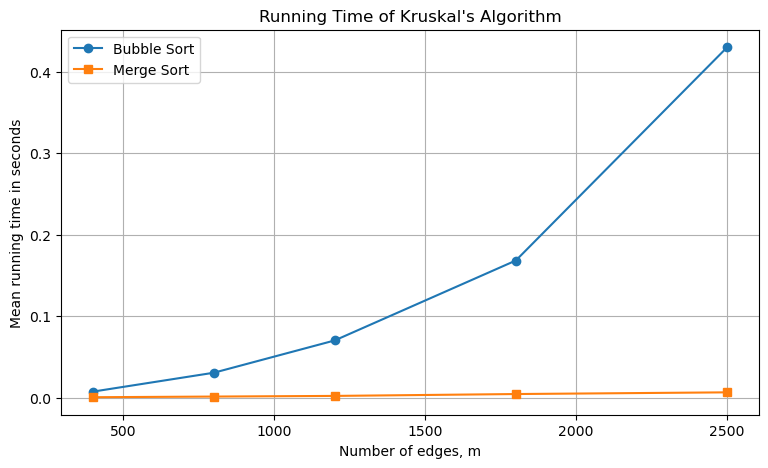

In [11]:
import random
import time
import matplotlib.pyplot as plt


def generate_connected_graph(number_of_vertices, number_of_edges, seed):
    minimum_edges = number_of_vertices - 1
    maximum_edges = number_of_vertices * (number_of_vertices - 1) // 2

    if number_of_edges < minimum_edges or number_of_edges > maximum_edges:
        raise ValueError('The requested number of edges is invalid.')

    generator = random.Random(seed)
    vertices = list(range(number_of_vertices))
    edges = []
    used_pairs = set()

    # First construct a random spanning tree, ensuring connectivity.
    for vertex in range(1, number_of_vertices):
        earlier_vertex = generator.randrange(vertex)
        pair = (earlier_vertex, vertex)
        used_pairs.add(pair)
        edges.append((earlier_vertex, vertex, generator.randint(1, 100000)))

    # Add distinct random edges.
    while len(edges) < number_of_edges:
        u = generator.randrange(number_of_vertices)
        v = generator.randrange(number_of_vertices)

        if u == v:
            continue

        pair = (min(u, v), max(u, v))

        if pair in used_pairs:
            continue

        used_pairs.add(pair)
        edges.append((u, v, generator.randint(1, 100000)))

    generator.shuffle(edges)
    return vertices, edges


def mean_running_time(vertices, edges, sorting_function, repetitions=3):
    start = time.perf_counter()
    final_weight = None

    for repetition in range(repetitions):
        tree, final_weight, comparisons = kruskal(
            vertices, edges, sorting_function
        )

    elapsed = time.perf_counter() - start
    return elapsed / repetitions, final_weight


graph_sizes = [
    (100, 400),
    (150, 800),
    (200, 1200),
    (250, 1800),
    (300, 2500)
]

edge_counts = []
bubble_times = []
merge_times = []

for experiment, (n, m) in enumerate(graph_sizes):
    random_vertices, random_edges = generate_connected_graph(
        n, m, seed=500 + experiment
    )

    bubble_time, bubble_weight = mean_running_time(
        random_vertices, random_edges, bubble_sort_edges
    )

    merge_time, merge_weight = mean_running_time(
        random_vertices, random_edges, merge_sort_edges
    )

    assert bubble_weight == merge_weight

    edge_counts.append(m)
    bubble_times.append(bubble_time)
    merge_times.append(merge_time)

    print(
        f'n={n:3d}, m={m:4d} | '
        f'Bubble={bubble_time:.6f}s | '
        f'Merge={merge_time:.6f}s | '
        f'MST weight={bubble_weight}'
    )

plt.figure(figsize=(9, 5))
plt.plot(edge_counts, bubble_times, marker='o', label='Bubble Sort')
plt.plot(edge_counts, merge_times, marker='s', label='Merge Sort')
plt.xlabel('Number of edges, m')
plt.ylabel('Mean running time in seconds')
plt.title("Running Time of Kruskal's Algorithm")
plt.legend()
plt.grid(True)
plt.show()


## Interpretation

Both implementations produce the same minimum weight because both process edges in nondecreasing order. Their growth rates are:

```text
Bubble Sort: Theta(m^2)
Merge Sort:  Theta(m log m)
```

Therefore, the Bubble Sort curve rises much more rapidly than the Merge Sort curve as the number of edges increases.


# Exercises

## Exercise 1: Manual Construction

Use the following graph:

```python
exercise_vertices = ['A', 'B', 'C', 'D', 'E', 'F']
exercise_edges = [
    ('A', 'B', 10), ('A', 'C', 16), ('A', 'D', 11),
    ('A', 'E', 10), ('A', 'F', 17), ('B', 'C', 9.5),
    ('B', 'F', 19.5), ('C', 'D', 7), ('C', 'F', 12),
    ('D', 'E', 8), ('D', 'F', 7), ('E', 'F', 9)
]
```

1. Trace Kruskal's algorithm, showing the accepted and rejected edges.
2. Find the MST and verify its total weight using both sorting methods.
3. Get all possible MSTs for the given graph.

## Exercise 2: Equal Weights and Non-uniqueness

Let V = {A, B, C, D}. Give the four boundary edges of the cycle A-B-C-D-A weight 1, and give diagonals AC and BD weight 2.

1. Change the order of the four weight-1 edges and record the resulting MSTs.
2. Explain why the MST may not be unique although every MST has the same total weight.

## Exercise 3: Quick Sort

Implement:

```python
def quick_sort_edges(edges):
    # Return sorted_edges and comparison_count
    pass
```

1. Add Quick Sort to Kruskal's algorithm and verify that the MST weight is unchanged.
2. Add Quick Sort to the running-time graph and compare its curve with Bubble Sort and Merge Sort.

## Exercise 4:

For a random graph with fixed n = 250 vertices, use:

```text
m = 500, 1000, 1500, 2000, 3000 edges
```

and plot the running times of Kruskal's algorithm involving Bubble Sort, Merge Sort and Quick Sort against m.


## Exercise 1

('C', 'D', 7) $\rightarrow$ ACCEPTED (Connects C and D)

('D', 'F', 7) $\rightarrow$ ACCEPTED (Connects D and F)

('D', 'E', 8) $\rightarrow$ ACCEPTED (Connects E to the component)

('E', 'F', 9) $\rightarrow$ REJECTED: cycle (E and F are already connected)

('B', 'C', 9.5) $\rightarrow$ ACCEPTED (Connects B)

('A', 'B', 10) $\rightarrow$ ACCEPTED (Connects A)

In [19]:
#Exercise 2
vertices_2 = ['A', 'B', 'C', 'D']

edges_2 = [
    ('A', 'B', 1),
    ('B', 'C', 1),
    ('C', 'D', 1),
    ('D', 'A', 1),
    ('A', 'C', 2),
    ('B', 'D', 2)
]

# Different orders of the weight-1 edges
orders = [
    [
        ('A', 'B', 1),
        ('B', 'C', 1),
        ('C', 'D', 1),
        ('D', 'A', 1)
    ],
    [
        ('A', 'B', 1),
        ('C', 'D', 1),
        ('B', 'C', 1),
        ('D', 'A', 1)
    ],
    [
        ('A', 'B', 1),
        ('D', 'A', 1),
        ('B', 'C', 1),
        ('C', 'D', 1)
    ],
    [
        ('B', 'C', 1),
        ('C', 'D', 1),
        ('D', 'A', 1),
        ('A', 'B', 1)
    ]
]

for number, weight_one_order in enumerate(orders, 1):

    ordered_edges = weight_one_order + [
        ('A', 'C', 2),
        ('B', 'D', 2)
    ]

    mst, weight, comparisons = kruskal(
        vertices_2,
        ordered_edges,
        lambda edges: (edges.copy(), 0)
    )

    print("Order", number)
    print("MST:", mst)
    print("Total weight:", weight)
    print()

Order 1
MST: [('A', 'B', 1), ('B', 'C', 1), ('C', 'D', 1)]
Total weight: 3

Order 2
MST: [('A', 'B', 1), ('C', 'D', 1), ('B', 'C', 1)]
Total weight: 3

Order 3
MST: [('A', 'B', 1), ('D', 'A', 1), ('B', 'C', 1)]
Total weight: 3

Order 4
MST: [('B', 'C', 1), ('C', 'D', 1), ('D', 'A', 1)]
Total weight: 3



In [20]:
exercise_vertices = ['A', 'B', 'C', 'D', 'E', 'F']

exercise_edges = [
    ('A', 'B', 10),
    ('A', 'C', 16),
    ('A', 'D', 11),
    ('A', 'E', 10),
    ('A', 'F', 17),
    ('B', 'C', 9.5),
    ('B', 'F', 19.5),
    ('C', 'D', 7),
    ('C', 'F', 12),
    ('D', 'E', 8),
    ('D', 'F', 7),
    ('E', 'F', 9)
]

In [23]:
#Exercise 3
def quick_sort_edges(edges):
    sorted_edges = edges.copy()
    comparisons = 0

    def quicksort(low, high):
        nonlocal comparisons

        if low >= high:
            return

        pivot = sorted_edges[high][2]

        i = low - 1

        for j in range(low, high):
            comparisons += 1

            if sorted_edges[j][2] <= pivot:
                i += 1
                sorted_edges[i], sorted_edges[j] = (
                    sorted_edges[j],
                    sorted_edges[i]
                )

        sorted_edges[i + 1], sorted_edges[high] = (
            sorted_edges[high],
            sorted_edges[i + 1]
        )

        pivot_index = i + 1

        quicksort(low, pivot_index - 1)
        quicksort(pivot_index + 1, high)

    quicksort(0, len(sorted_edges) - 1)

    return sorted_edges, comparisons

quick_mst, quick_weight, quick_comparisons = kruskal(
    exercise_vertices,
    exercise_edges,
    quick_sort_edges,
    show_steps=True
)

print()
print("MST using Quick Sort:", quick_mst)
print("Total weight:", quick_weight)
print("Sorting comparisons:", quick_comparisons)

('C', 'D', 7) | Find( C ) = C | Find( D ) = D | ACCEPTED
('D', 'F', 7) | Find( D ) = C | Find( F ) = F | ACCEPTED
('D', 'E', 8) | Find( D ) = C | Find( E ) = E | ACCEPTED
('E', 'F', 9) | Find( E ) = C | Find( F ) = C | REJECTED: cycle
('B', 'C', 9.5) | Find( B ) = B | Find( C ) = C | ACCEPTED
('A', 'B', 10) | Find( A ) = A | Find( B ) = C | ACCEPTED

MST using Quick Sort: [('C', 'D', 7), ('D', 'F', 7), ('D', 'E', 8), ('B', 'C', 9.5), ('A', 'B', 10)]
Total weight: 41.5
Sorting comparisons: 31


In [21]:
bubble_mst, bubble_weight, _ = kruskal(
    exercise_vertices,
    exercise_edges,
    bubble_sort_edges
)

merge_mst, merge_weight, _ = kruskal(
    exercise_vertices,
    exercise_edges,
    merge_sort_edges
)

quick_mst, quick_weight, _ = kruskal(
    exercise_vertices,
    exercise_edges,
    quick_sort_edges
)

print("Bubble Sort MST weight:", bubble_weight)
print("Merge Sort MST weight:", merge_weight)
print("Quick Sort MST weight:", quick_weight)

assert bubble_weight == merge_weight == quick_weight

print("All three sorting methods produce the same MST weight.")

Bubble Sort MST weight: 41.5
Merge Sort MST weight: 41.5
Quick Sort MST weight: 41.5
All three sorting methods produce the same MST weight.


n=250, m=500 | Bubble=0.021241s | Merge=0.001416s | Quick=0.001033s | MST weight=7504284
n=250, m=1000 | Bubble=0.090683s | Merge=0.003058s | Quick=0.002177s | MST weight=3743688
n=250, m=1500 | Bubble=0.145788s | Merge=0.003595s | Quick=0.002789s | MST weight=2338351
n=250, m=2000 | Bubble=0.263355s | Merge=0.007751s | Quick=0.003520s | MST weight=1907189
n=250, m=3000 | Bubble=0.682367s | Merge=0.008213s | Quick=0.005868s | MST weight=1163004


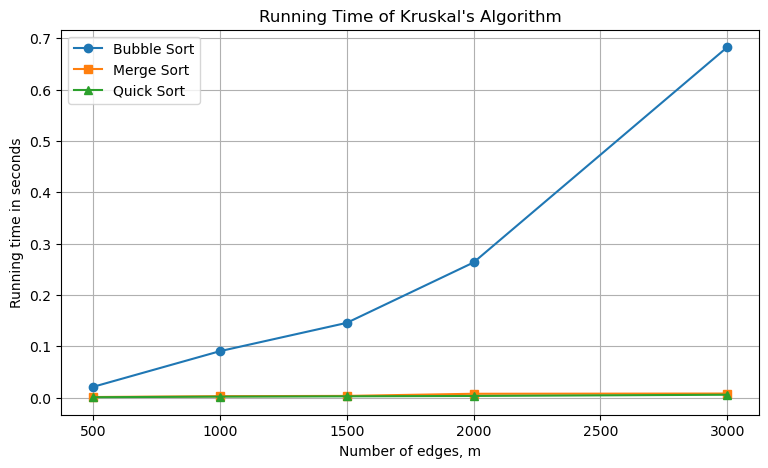

In [24]:
#Exercise 4

import time
import matplotlib.pyplot as plt

n = 250

edge_counts = [500, 1000, 1500, 2000, 3000]

bubble_times = []
merge_times = []
quick_times = []

for experiment, m in enumerate(edge_counts):

    vertices, edges = generate_connected_graph(
        n,
        m,
        seed=1000 + experiment
    )

    # Bubble Sort
    start = time.perf_counter()

    bubble_mst, bubble_weight, _ = kruskal(
        vertices,
        edges,
        bubble_sort_edges
    )

    bubble_time = time.perf_counter() - start

    # Merge Sort
    start = time.perf_counter()

    merge_mst, merge_weight, _ = kruskal(
        vertices,
        edges,
        merge_sort_edges
    )

    merge_time = time.perf_counter() - start

    # Quick Sort
    start = time.perf_counter()

    quick_mst, quick_weight, _ = kruskal(
        vertices,
        edges,
        quick_sort_edges
    )

    quick_time = time.perf_counter() - start

    # Verify correctness
    assert bubble_weight == merge_weight == quick_weight

    bubble_times.append(bubble_time)
    merge_times.append(merge_time)
    quick_times.append(quick_time)

    print(
        f"n={n}, m={m} | "
        f"Bubble={bubble_time:.6f}s | "
        f"Merge={merge_time:.6f}s | "
        f"Quick={quick_time:.6f}s | "
        f"MST weight={bubble_weight}"
    )
    
plt.figure(figsize=(9, 5))

plt.plot(
    edge_counts,
    bubble_times,
    marker='o',
    label='Bubble Sort'
)

plt.plot(
    edge_counts,
    merge_times,
    marker='s',
    label='Merge Sort'
)

plt.plot(
    edge_counts,
    quick_times,
    marker='^',
    label='Quick Sort'
)

plt.xlabel('Number of edges, m')
plt.ylabel('Running time in seconds')
plt.title("Running Time of Kruskal's Algorithm")
plt.legend()
plt.grid(True)

plt.show()